In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

# Unduh dataset MNIST (60.000 data latih, 10.000 data uji)
(train_images, train_labels), (test_images, test_labels) = datasets.mnist.load_data()

# Reshape dari (28, 28) menjadi (28, 28, 1) agar sesuai input Conv2D & normalisasi (0-1)
train_images = train_images.reshape((60000, 28, 28, 1)) / 255.0
test_images = test_images.reshape((10000, 28, 28, 1)) / 255.0

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


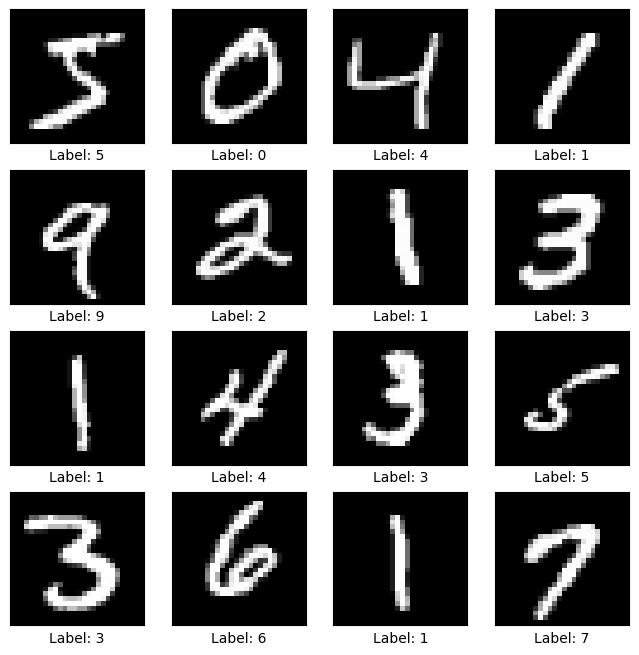

In [2]:
plt.figure(figsize=(8, 8))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i].reshape(28, 28), cmap='gray')
    plt.xlabel(f"Label: {train_labels[i]}")
plt.show()

In [3]:
model = models.Sequential([
    # Input shape (28, 28, 1) karena gambar hitam-putih (1 channel)
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),

    # Fully Connected Layer
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.2), # Mencegah overfitting
    layers.Dense(10)     # 10 output kelas (angka 0 sampai 9)
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,322 (364.54 KB)

 Trainable params: 93,322 (364.54 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

history = model.fit(
    train_images, train_labels,
    epochs=10,
    batch_size=64,
    validation_data=(test_images, test_labels)
)

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 26s 18ms/step - accuracy: 0.9316 - loss: 0.2187 - val_accuracy: 0.9842 - val_loss: 0.0492
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9815 - loss: 0.0609 - val_accuracy: 0.9876 - val_loss: 0.0399
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9867 - loss: 0.0430 - val_accuracy: 0.9897 - val_loss: 0.0323
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9901 - loss: 0.0335 - val_accuracy: 0.9904 - val_loss: 0.0265
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9913 - loss: 0.0284 - val_accuracy: 0.9914 - val_loss: 0.0254
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9927 - loss: 0.0237 - val_accuracy: 0.9920 - val_loss: 0.0254
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9938 - loss: 0.0199 - val_accuracy: 0.9930 - val_loss: 0.0244
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9948 - loss: 0.0169 - val_accuracy: 

313/313 - 3s - 10ms/step - accuracy: 0.9907 - loss: 0.0351

Akurasi Testing MNIST: 99.07%


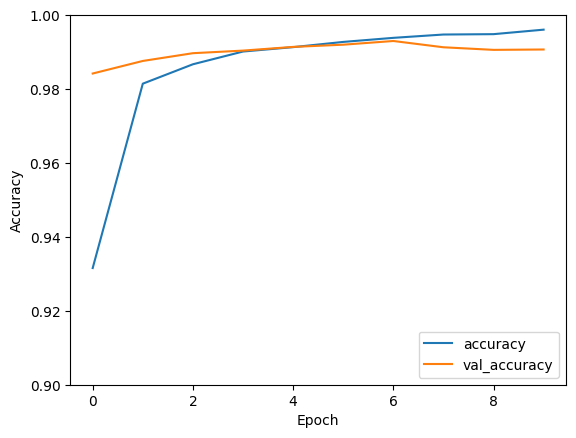

In [5]:
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print(f"\nAkurasi Testing MNIST: {test_acc * 100:.2f}%")

plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.9, 1.0])
plt.legend(loc='lower right')
plt.show()

## Analisis Hasil

Seluruh angka pada bagian ini diambil dari output aktual notebook.

### Arsitektur dan Konfigurasi

| Item | Nilai |
|---|---|
| Dataset | MNIST (60.000 latih, 10.000 uji) |
| Input | 28 x 28 x 1 |
| Konvolusi | 32, 64, 64 filter (3x3, ReLU) |
| Pooling | MaxPooling 2x2 setelah konvolusi 1 dan 2 |
| Fully connected | Dense 64 (ReLU) + Dropout 0.2 |
| Output | Dense 10 (logits) |
| Total parameter | 93.322 |
| Epoch | 10 |
| Batch size | 64 |
| Optimizer | Adam |
| Loss | Sparse Categorical Crossentropy |

### Riwayat Training

| Epoch | Train Acc | Train Loss | Val Acc | Val Loss |
|---:|---:|---:|---:|---:|
| 1 | 0.9316 | 0.2187 | 0.9842 | 0.0492 |
| 2 | 0.9815 | 0.0609 | 0.9876 | 0.0399 |
| 3 | 0.9867 | 0.0430 | 0.9897 | 0.0323 |
| 4 | 0.9901 | 0.0335 | 0.9904 | 0.0265 |
| 5 | 0.9913 | 0.0284 | 0.9914 | 0.0254 |
| 6 | 0.9927 | 0.0237 | 0.9920 | 0.0254 |
| 7 | 0.9938 | 0.0199 | **0.9930** | **0.0244** |
| 8 | 0.9948 | 0.0169 | 0.9913 | 0.0296 |
| 9 | 0.9948 | 0.0154 | 0.9906 | 0.0341 |
| 10 | 0.9961 | 0.0120 | 0.9907 | 0.0351 |

### Hasil Evaluasi

| Metrik | Nilai |
|---|---|
| Akurasi data uji | **0.9907 (99.07%)** |
| Test loss | 0.0351 |
| Jumlah salah | sekitar 93 dari 10.000 gambar |

### Pembahasan

1. **Akurasi sangat tinggi sejak epoch pertama.** Pada Epoch 1 akurasi validasi sudah **98.42%**, lalu naik ke **99.07%** pada Epoch 10. CNN efektif mengenali pola spasial angka karena memakai konvolusi, berbeda dari MLP yang harus meratakan gambar menjadi vektor.
2. **Konvergensi cepat.** Akurasi validasi melewati 99% pada Epoch 4 dan stabil di kisaran 99% setelahnya. Sebagian besar peningkatan terjadi pada beberapa epoch pertama.
3. **Akurasi validasi terbaik ada di Epoch 7.** Nilainya **99.30%** dengan `val_loss` **0.0244**. Setelah Epoch 7, akurasi validasi sedikit menurun (99.13%, 99.06%, 99.07%) dan `val_loss` naik (0.0296, 0.0341, 0.0351).
4. **Overfitting ringan mulai muncul setelah Epoch 7.** Akurasi training terus naik dari **99.38%** ke **99.61%**, tetapi akurasi validasi tidak ikut naik. Jarak train dan validasi pada Epoch 10 adalah **0.54 poin persentase**, tergolong kecil tetapi polanya konsisten.
5. **Early stopping di Epoch 7 berpotensi memberi hasil lebih baik.** Jika training dihentikan pada Epoch 7, akurasi validasi **99.30%** dan loss **0.0244**, lebih baik daripada hasil akhir **99.07%** dan **0.0351**.
6. **Dropout 0.2 membantu menekan overfitting.** Tanpa dropout, jarak train dan validasi kemungkinan lebih besar. Namun dropout belum sepenuhnya mencegah penurunan performa validasi setelah Epoch 7.
7. **Waktu training efisien.** Epoch pertama 26 detik karena proses inisialisasi, epoch berikutnya sekitar 4 detik. Total training sekitar 62 detik untuk 10 epoch.
8. **Perbandingan dengan MLP pada JS13.** MLP terbaik di JS13 memperoleh akurasi **97.28%** (256-128 ReLU), sedangkan CNN ini memperoleh **99.07%**, sekitar **1.79 poin** lebih tinggi. CNN juga memakai parameter jauh lebih sedikit (**93.322** berbanding **235.146**) karena konvolusi berbagi bobot.
9. **Data uji dipakai sebagai `validation_data`.** Karena tidak ada validation set terpisah, kurva validasi di atas sebenarnya adalah performa pada data uji. Pemilihan jumlah epoch berdasarkan kurva ini membuat hasil akhir sedikit optimistis. Untuk evaluasi yang lebih ketat, data latih seharusnya dipecah lagi menjadi train dan validation, lalu data uji hanya dipakai sekali di akhir.

### Kesimpulan

1. Model CNN mencapai akurasi **99.07%** pada data uji MNIST dengan **93.322** parameter.
2. Performa terbaik tercatat pada **Epoch 7 (99.30%)**, sebelum overfitting ringan muncul.
3. CNN mengungguli MLP pada tugas JS13 dengan akurasi lebih tinggi dan jumlah parameter lebih kecil.
4. Penambahan **early stopping** dan **validation set terpisah** akan membuat evaluasi lebih ketat dan hasil lebih dapat dipercaya.